# Restaurant Data Analysis Project
**Objective:** Explore restaurant cuisine, location, ratings, price ranges, online delivery, table booking, chains, and voting behavior.

**Tools:** Python, Pandas, NumPy, Matplotlib  
**Dataset:** `Dataset.csv` (9,551 rows, 21 columns)

This notebook follows a portfolio workflow: business questions, data loading, quality checks, analysis, visualizations, and conclusions.

## 1. Business questions
- Which cuisines are most common?
- Which city has the most restaurants, and which has the highest average rating?
- How are restaurants distributed across price ranges?
- Do ratings differ by online delivery availability?
- What rating band is most common?
- Which cuisine combinations and chains are frequent?
- How do votes relate to ratings?
- How does price range relate to delivery and table booking?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Dataset.csv")
print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

## 2. Data quality checks
Missing cuisine values are labeled `Unknown` for analysis.

In [2]:
display(df.isna().sum().sort_values(ascending=False).head(10))
df["Cuisines"] = df["Cuisines"].fillna("Unknown")
df["City"] = df["City"].fillna("Unknown")
print("Rows:", len(df), "| Columns:", len(df.columns))

Cuisines                9
Restaurant ID           0
Currency                0
Rating text             0
Rating color            0
Aggregate rating        0
Price range             0
Switch to order menu    0
Is delivering now       0
Has Online delivery     0
dtype: int64

Rows: 9551 | Columns: 21


## 3. Cuisine popularity

,Restaurants,Percentage of dataset records (%)
Cuisines,,
North Indian,3960,41.46
Chinese,2735,28.64
Fast Food,1986,20.79


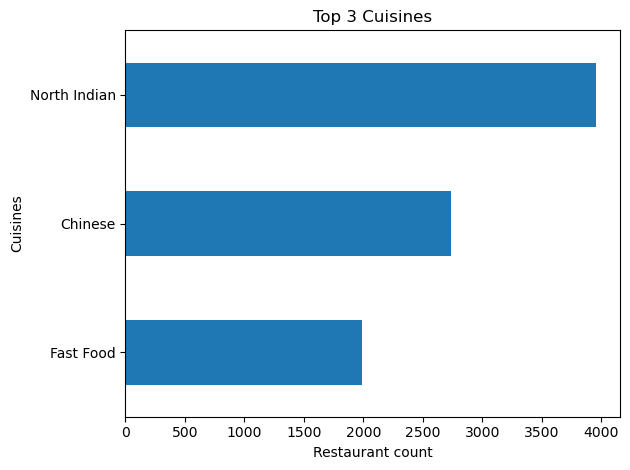

In [3]:
cuisine_counts = df["Cuisines"].str.split(",").explode().str.strip().value_counts()
top3 = cuisine_counts.head(3)
display(pd.DataFrame({"Restaurants": top3, "Percentage of dataset records (%)": (top3 / len(df) * 100).round(2)}))
top3.sort_values().plot(kind="barh", title="Top 3 Cuisines")
plt.xlabel("Restaurant count")
plt.tight_layout()
plt.show()

## 4. City analysis

City with most restaurants: New Delhi 5473
Highest average-rated city: Inner City 4.9


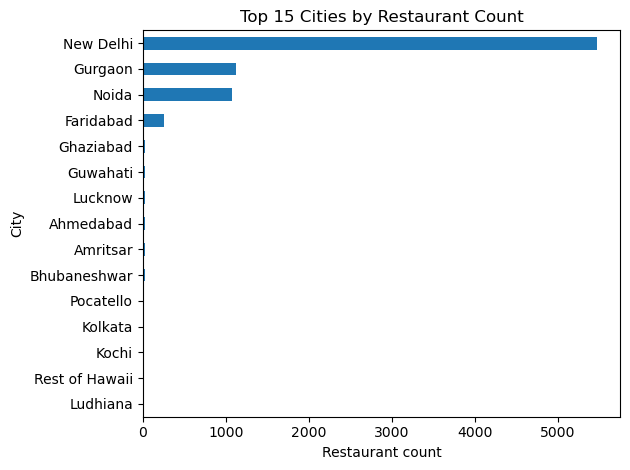

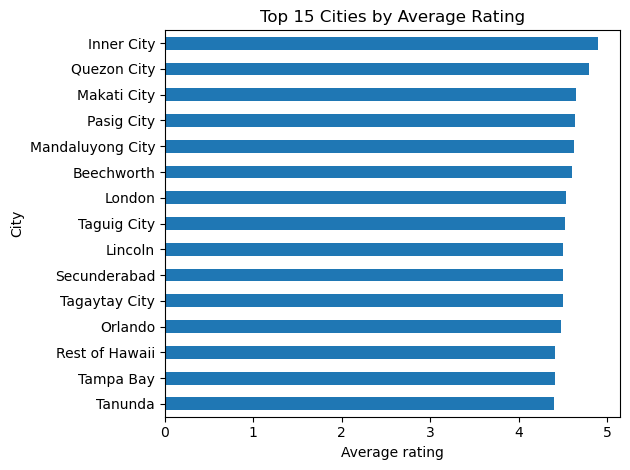

In [4]:
city_counts = df["City"].value_counts()
city_avg_rating = df.groupby("City")["Aggregate rating"].mean().sort_values(ascending=False)
print("City with most restaurants:", city_counts.idxmax(), city_counts.max())
print("Highest average-rated city:", city_avg_rating.idxmax(), round(city_avg_rating.max(), 3))
city_counts.head(15).sort_values().plot(kind="barh", title="Top 15 Cities by Restaurant Count")
plt.xlabel("Restaurant count"); plt.tight_layout(); plt.show()
city_avg_rating.head(15).sort_values().plot(kind="barh", title="Top 15 Cities by Average Rating")
plt.xlabel("Average rating"); plt.tight_layout(); plt.show()

## 5. Price-range distribution

,Restaurants,Percentage (%)
Price range,,
1,4444,46.53
2,3113,32.59
3,1408,14.74
4,586,6.14


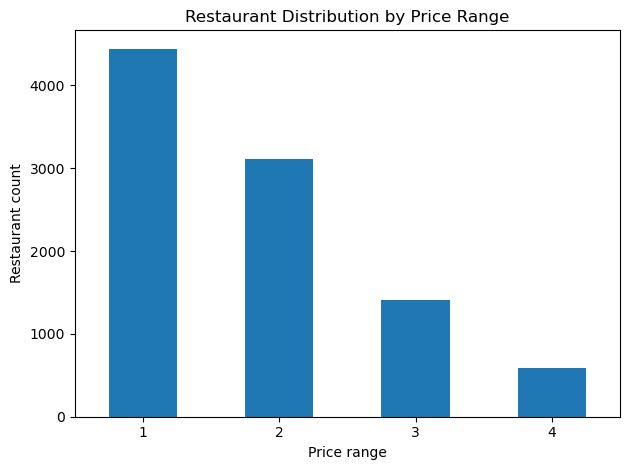

In [5]:
price_counts = df["Price range"].value_counts().sort_index()
display(pd.DataFrame({"Restaurants": price_counts, "Percentage (%)": (price_counts / len(df) * 100).round(2)}))
price_counts.plot(kind="bar", title="Restaurant Distribution by Price Range")
plt.xlabel("Price range"); plt.ylabel("Restaurant count"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## 6. Online delivery and ratings

,Restaurant share (%),Average rating
Has Online delivery,,
No,74.34,2.465
Yes,25.66,3.249


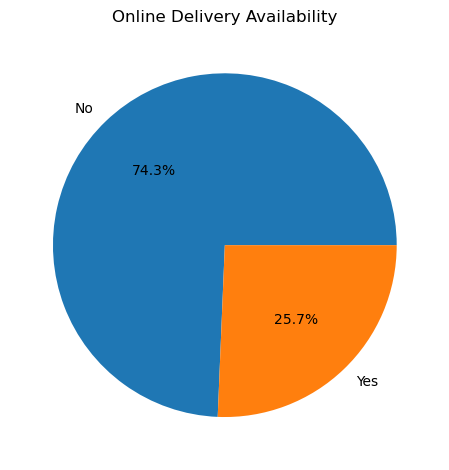

In [6]:
delivery_pct = (df["Has Online delivery"].value_counts(normalize=True) * 100).round(2)
delivery_avg_rating = df.groupby("Has Online delivery")["Aggregate rating"].mean().round(3)
display(pd.DataFrame({"Restaurant share (%)": delivery_pct, "Average rating": delivery_avg_rating}))
delivery_pct.plot(kind="pie", autopct="%1.1f%%", title="Online Delivery Availability")
plt.ylabel(""); plt.tight_layout(); plt.show()

## 7. Rating distribution and votes

Aggregate rating
0–0.99    2148
1–1.99       3
2–2.99    1430
3–3.99    4590
4–4.99    1380
5.0          0
Name: Restaurants, dtype: int64

Average votes: 156.91
Votes-rating correlation: 0.3137


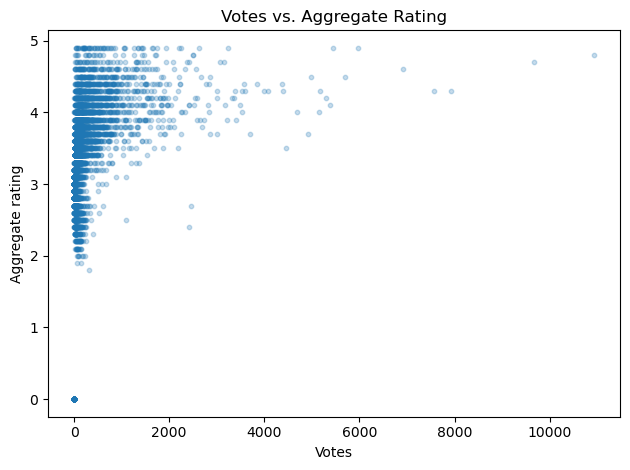

In [7]:
rating_bins = pd.cut(df["Aggregate rating"], bins=[-0.01, 0.99, 1.99, 2.99, 3.99, 4.99, 5.0],
    labels=["0–0.99", "1–1.99", "2–2.99", "3–3.99", "4–4.99", "5.0"])
display(rating_bins.value_counts().sort_index().rename("Restaurants"))
print("Average votes:", round(df["Votes"].mean(), 2))
print("Votes-rating correlation:", round(df[["Votes", "Aggregate rating"]].corr().iloc[0, 1], 4))
plt.scatter(df["Votes"], df["Aggregate rating"], alpha=0.25, s=10)
plt.title("Votes vs. Aggregate Rating"); plt.xlabel("Votes"); plt.ylabel("Aggregate rating")
plt.tight_layout(); plt.show()

## 8. Cuisine combinations and restaurant chains

In [8]:
display(df["Cuisines"].value_counts().head(10).rename("Restaurants"))
combo_stats = df.groupby("Cuisines").agg(Restaurants=("Restaurant ID","count"),
    Average_Rating=("Aggregate rating","mean"), Average_Votes=("Votes","mean"))
display(combo_stats[combo_stats["Restaurants"] >= 10].sort_values("Average_Rating", ascending=False).head(10))
name_counts = df["Restaurant Name"].value_counts()
chain_names = name_counts[name_counts > 1].index
chain_stats = df[df["Restaurant Name"].isin(chain_names)].groupby("Restaurant Name").agg(
    Locations=("Restaurant ID","count"), Average_Rating=("Aggregate rating","mean"),
    Average_Votes=("Votes","mean")).sort_values("Locations", ascending=False)
display(chain_stats.head(10))

Cuisines
North Indian                      936
North Indian, Chinese             511
Chinese                           354
Fast Food                         354
North Indian, Mughlai             334
Cafe                              299
Bakery                            218
North Indian, Mughlai, Chinese    197
Bakery, Desserts                  170
Street Food                       149
Name: Restaurants, dtype: int64

,Restaurants,Average_Rating,Average_Votes
Cuisines,,,
Modern Indian,11,4.345455,1123.181818
Indian,18,4.250000,337.111111
Seafood,14,4.114286,380.857143
Thai,16,4.100000,206.187500
"Cafe, Continental, Italian",10,4.080000,183.000000
"American, Burger",13,4.076923,490.076923
"Japanese, Sushi",18,4.044444,284.388889
"Pizza, Italian",19,3.668421,318.210526
American,31,3.667742,251.677419


,Locations,Average_Rating,Average_Votes
Restaurant Name,,,
Cafe Coffee Day,83,2.419277,29.253012
Domino's Pizza,79,2.740506,84.088608
Subway,63,2.907937,97.206349
Green Chick Chop,51,2.672549,18.901961
McDonald's,48,3.339583,110.229167
Keventers,34,2.870588,37.147059
Pizza Hut,30,3.320000,165.366667
Giani,29,2.689655,29.448276
Baskin Robbins,28,1.860714,15.285714


## 9. Geographic distribution

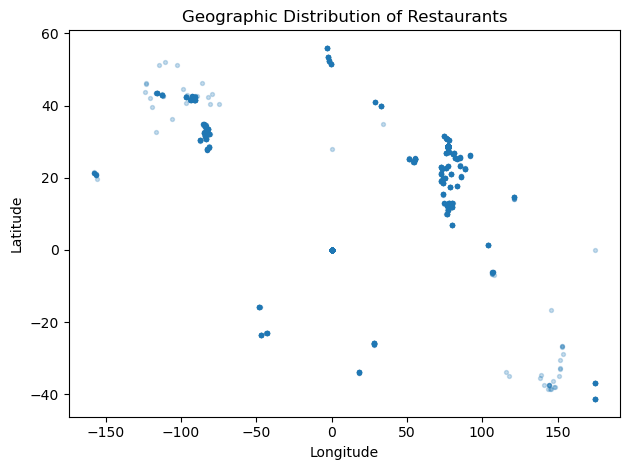

In [9]:
plt.scatter(df["Longitude"], df["Latitude"], alpha=0.25, s=8)
plt.title("Geographic Distribution of Restaurants"); plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.tight_layout(); plt.show()

## 10. Price range vs service availability

Has Online delivery,No,Yes
Price range,,
1,84.23,15.77
2,58.69,41.31
3,70.81,29.19
4,90.96,9.04


Has Table booking,No,Yes
Price range,,
1,99.98,0.02
2,92.32,7.68
3,54.26,45.74
4,53.24,46.76


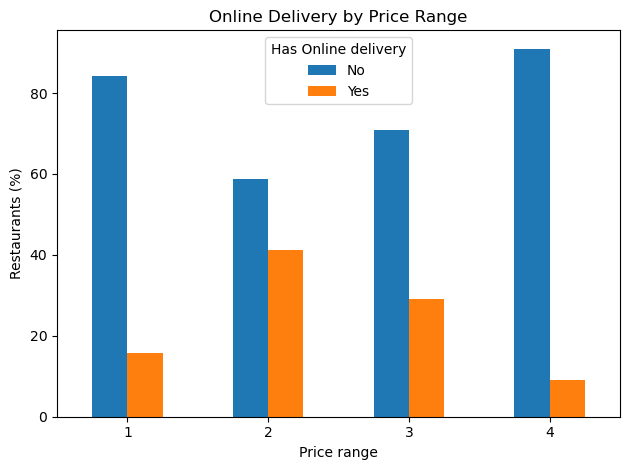

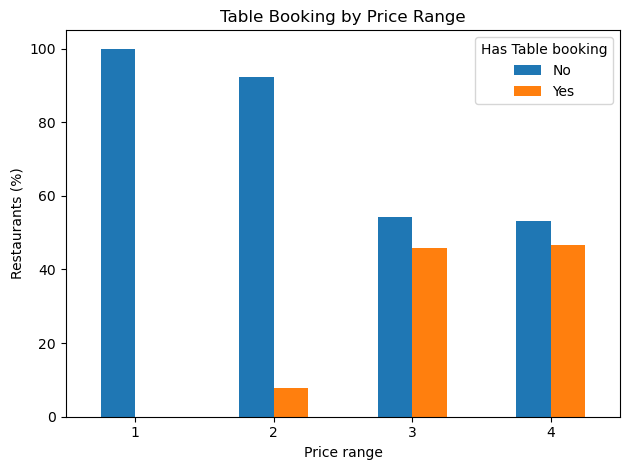

In [10]:
delivery_by_price = pd.crosstab(df["Price range"], df["Has Online delivery"], normalize="index") * 100
booking_by_price = pd.crosstab(df["Price range"], df["Has Table booking"], normalize="index") * 100
display(delivery_by_price.round(2)); display(booking_by_price.round(2))
delivery_by_price.plot(kind="bar", title="Online Delivery by Price Range")
plt.ylabel("Restaurants (%)"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
booking_by_price.plot(kind="bar", title="Table Booking by Price Range")
plt.ylabel("Restaurants (%)"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 11. Conclusions and limitations
- North Indian, Chinese, and Fast Food are the most common individual cuisines.
- New Delhi has the largest restaurant count in this dataset.
- Price Range 1 is the most common category.
- Restaurants with online delivery have a higher average rating in this dataset. This is an association, not proof that delivery causes higher ratings.
- Votes and ratings have a positive but limited correlation.
- Table booking is more prevalent in higher price ranges.
- The CSV has no written review comments. `Rating text` is a category label, so review keyword and review-length analysis need an additional source.